# Ames Housing — Data Analysis Notebook

**DA | Data source:** `data/processed/train_cleaned.csv`

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from IPython.display import display, Markdown

# Locate the repository root whether Jupyter starts at the repo or notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "data/processed/train_cleaned.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train_cleaned.csv. Hãy mở notebook trong thư mục project.")
DATA = ROOT / "data/processed"
train = pd.read_csv(DATA / "train_cleaned.csv", keep_default_na=False, na_values=[""])
extended = pd.read_csv(DATA / "train_extended.csv", keep_default_na=False, na_values=[""])
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 120, "axes.titlesize": 13})
print(f"Project: {ROOT}\nTrain shape: {train.shape}\nSalePrice target present: {'SalePrice' in train.columns}")

Project: d:\Introduction-to-BA
Train shape: (1460, 89)
SalePrice target present: True


## Task 1 — Data understanding

Xác định quy mô dữ liệu, target, loại biến theo ý nghĩa phân tích và chất lượng dữ liệu


In [2]:

clean_path = DATA / "train_cleaned.csv"
ext_path = DATA / "train_extended.csv"
clean_cols, ext_cols = list(train.columns), list(extended.columns)
ids_equal = set(train.Id) == set(extended.Id)
a = train.set_index("Id").sort_index()
b = extended.set_index("Id").sort_index()
diff_by_col = {}
if ids_equal:
    for col in [c for c in clean_cols if c in ext_cols and c != "Id"]:
        diff = a[col].astype("string").fillna("<NA>").ne(b[col].astype("string").fillna("<NA>"))
        if diff.any(): diff_by_col[col] = int(diff.sum())
comparison = pd.DataFrame([
    ("cleaned shape", str(train.shape)), ("extended shape", str(extended.shape)),
    ("same column order", clean_cols == ext_cols),
    ("columns only in cleaned", [c for c in clean_cols if c not in ext_cols]),
    ("columns only in extended", [c for c in ext_cols if c not in clean_cols]),
    ("same Id set", ids_equal), ("cell differences", sum(diff_by_col.values())),
    ("different columns/values", diff_by_col),
    ("cleaned SHA256", hashlib.sha256(clean_path.read_bytes()).hexdigest()),
    ("extended SHA256", hashlib.sha256(ext_path.read_bytes()).hexdigest()),
], columns=["check", "result"])
display(comparison)


display(train[["SalePrice", "GrLivArea", "LotArea", "OverallQual", "YearBuilt"]].describe().T.round(2))
print(f"Missing cells total: {train.isna().sum().sum():,}")

,check,result
0,cleaned shape,"(1460, 89)"
1,extended shape,"(1460, 89)"
2,same column order,True
3,columns only in cleaned,[]
4,columns only in extended,[]
5,same Id set,True
6,cell differences,0
7,different columns/values,{}
8,cleaned SHA256,bcb896ed6faffa77e6fbf56c85f98006e150f784b1ac1b...
9,extended SHA256,bcb896ed6faffa77e6fbf56c85f98006e150f784b1ac1b...


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.20,79442.50,34900.0,129975.0,163000.0,214000.00,755000.0
GrLivArea,1460.0,1515.46,525.48,334.0,1129.5,1464.0,1776.75,5642.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.5,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.0,6.0,7.00,10.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.0,1973.0,2000.00,2010.0


Missing cells total: 357


### Phân loại biến

- **Target:** `SalePrice` (USD).
- **ID:** `Id`; không dùng làm yếu tố giá.
- **Numerical measurements:** diện tích, số phòng/garage, năm xây dựng và các phép đo khác.
- **Ordinal:** `OverallQual`, `OverallCond` và các thang chất lượng.
- **Categorical:** `Neighborhood`, zoning, kiểu nhà và các trường phân loại; `MSSubClass` là mã loại nhà dù được lưu dạng số.
- **Synthetic:** tám trường ngữ cảnh mô phỏng, có nhãn ở phần Task 6.

In [3]:

desc_path = ROOT / "house-prices-advanced-regression-techniques/data_description.txt"
import re
base_desc = {}
for line in desc_path.read_text(encoding="utf-8", errors="replace").splitlines():
    match = re.match(r"^([A-Za-z0-9_]+):\s*(.+?)\s*$", line)
    if match: base_desc[match.group(1)] = match.group(2)
synthetic = ["DistanceToSchoolKm", "DistanceToHospitalKm", "DistanceToTransitKm", "RenovationFlag", "YearsSinceRenovation", "DaysOnMarket", "SimulatedInterestRatePct", "SimulatedPriceIndex"]
rows=[]
ordinal=["OverallQual","OverallCond","ExterQual","ExterCond","BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","HeatingQC","KitchenQual","Functional","FireplaceQu","GarageFinish","GarageQual","GarageCond","PoolQC","Fence"]
for col in train.columns:
    if col == "SalePrice": kind, role, description = "Target: numeric continuous", "Target", "Sale price in USD"
    elif col == "Id": kind, role, description = "Identifier", "Key", "Unique property identifier"
    elif col in ordinal: kind, role, description = "Ordinal categorical", "Base feature", base_desc.get(col, "Ordinal quality/condition scale")
    elif col == "MSSubClass": kind, role, description = "Nominal category (integer code)", "Base feature", base_desc.get(col, "Dwelling class")
    elif col == "MoSold": kind, role, description = "Calendar month", "Base feature", base_desc.get(col, "Month sold")
    elif col == "RenovationFlag": kind, role, description = "Binary categorical", "Synthetic/derived", "1 if remodel year is after construction year"
    elif col in synthetic: kind, role, description = "Synthetic feature", "Synthetic/derived", "See docs/data_engineering/synthetic_assumptions.md"
    elif train[col].dtype == "object": kind, role, description = "Nominal categorical", "Base feature", base_desc.get(col, "Categorical field")
    else: kind, role, description = "Numeric", "Base feature", base_desc.get(col, "Numeric field")
    rows.append({"feature":col,"description":description,"role":role,"analysis_type":kind,"dtype":str(train[col].dtype),"missing":int(train[col].isna().sum()),"unique":int(train[col].nunique(dropna=True))})
feature_dictionary=pd.DataFrame(rows)
display(feature_dictionary)

,feature,description,role,analysis_type,dtype,missing,unique
0,Id,Unique property identifier,Key,Identifier,int64,0,1460
1,MSSubClass,Identifies the type of dwelling involved in th...,Base feature,Nominal category (integer code),int64,0,15
2,MSZoning,Identifies the general zoning classification o...,Base feature,Numeric,str,0,5
3,LotFrontage,Linear feet of street connected to property,Base feature,Numeric,float64,259,110
4,LotArea,Lot size in square feet,Base feature,Numeric,int64,0,1073
...,...,...,...,...,...,...,...
84,RenovationFlag,1 if remodel year is after construction year,Synthetic/derived,Binary categorical,int64,0,2
85,YearsSinceRenovation,See docs/data_engineering/synthetic_assumption...,Synthetic/derived,Synthetic feature,int64,0,61
86,DaysOnMarket,See docs/data_engineering/synthetic_assumption...,Synthetic/derived,Synthetic feature,int64,0,89
87,SimulatedInterestRatePct,See docs/data_engineering/synthetic_assumption...,Synthetic/derived,Synthetic feature,float64,0,5


### Từ điển trường bằng tiếng Việt

Bảng dưới đây là giải thích tiếng Việt cho toàn bộ cột, dùng để tra cứu ý nghĩa và loại biến khi trình bày kết quả.

In [5]:
vi_dictionary = pd.read_csv(ROOT / "reports/eda/data_dictionary_vi.csv")
display(vi_dictionary)

,Trường,Giải thích tiếng Việt,Vai trò,Loại biến,Đơn vị/thang đo,Missing
0,Id,Mã nhận diện duy nhất của căn nhà trong bộ dữ ...,Mã định danh,Mã định danh,xem mô tả/giá trị mã trong bộ dữ liệu,0
1,MSSubClass,"Mã loại hình nhà ở (ví dụ nhà 1 tầng, 2 tầng, ...",Biến gốc,Biến phân loại danh nghĩa (mã số),xem mô tả/giá trị mã trong bộ dữ liệu,0
2,MSZoning,Phân loại quy hoạch/khu chức năng của bất động...,Biến gốc,Biến phân loại danh nghĩa,xem mô tả/giá trị mã trong bộ dữ liệu,0
3,LotFrontage,"Chiều dài mặt tiền lô đất tiếp giáp với đường,...",Biến gốc,Biến số liên tục (diện tích),feet chiều dài,259
4,LotArea,"Diện tích lô đất, tính bằng feet vuông.",Biến gốc,Biến số liên tục (diện tích),feet vuông,0
...,...,...,...,...,...,...
84,RenovationFlag,Cờ cải tạo: bằng 1 nếu YearRemodAdd > YearBuil...,Synthetic/mô phỏng,Biến nhị phân,nhị phân 0/1,0
85,YearsSinceRenovation,"YrSold − YearRemodAdd, chặn tối thiểu ở 0. Nếu...",Synthetic/mô phỏng,Biến số liên tục,năm,0
86,DaysOnMarket,Số ngày đăng bán được mô phỏng theo accessibil...,Synthetic/mô phỏng,Biến số liên tục,ngày,0
87,SimulatedInterestRatePct,"Lãi suất giả định theo năm bán (6,5 − 0,2 × (Y...",Synthetic/mô phỏng,Biến số liên tục,điểm phần trăm,0


## Task 2 — Univariate analysis

Xem histogram/KDE và boxplot của các biến số chính; `OverallQual` là thang rời rạc nên dùng count chart. `Neighborhood` được mô tả bằng số giao dịch và phân phối giá theo khu vực.

,feature,n,mean,median,std,min,q1,q3,max,skewness
0,SalePrice,1460,180921.20,163000.0,79442.50,34900,129975.0,214000.00,755000,1.88
1,GrLivArea,1460,1515.46,1464.0,525.48,334,1129.5,1776.75,5642,1.37
2,LotArea,1460,10516.83,9478.5,9981.26,1300,7553.5,11601.50,215245,12.21
3,YearBuilt,1460,1971.27,1973.0,30.20,1872,1954.0,2000.00,2010,-0.61
4,OverallQual,1460,6.10,6.0,1.38,1,5.0,7.00,10,0.22


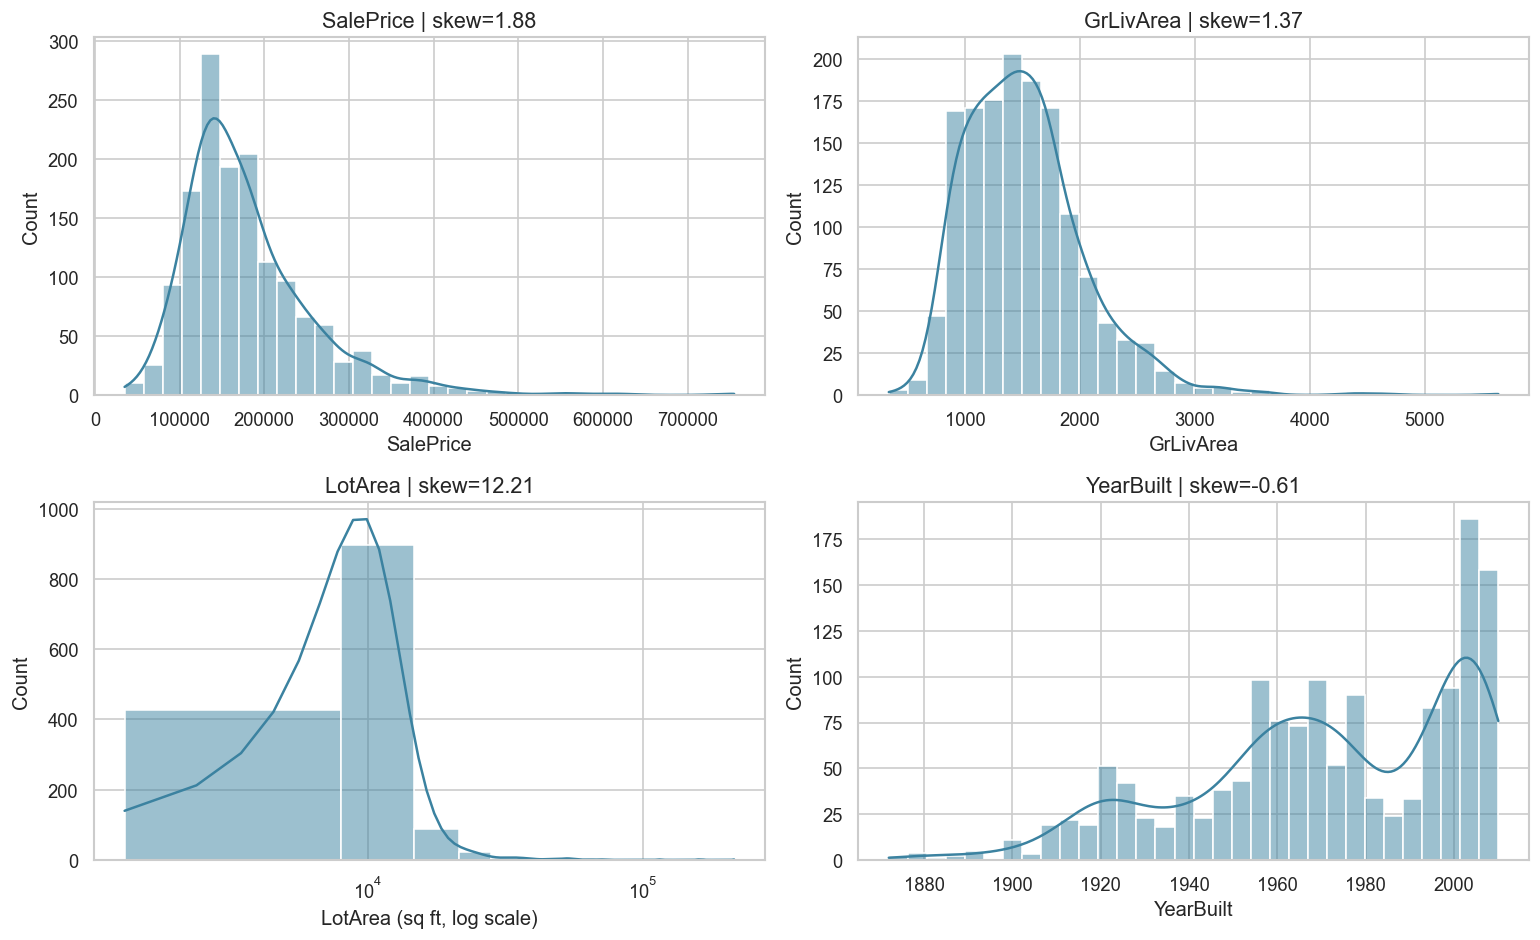

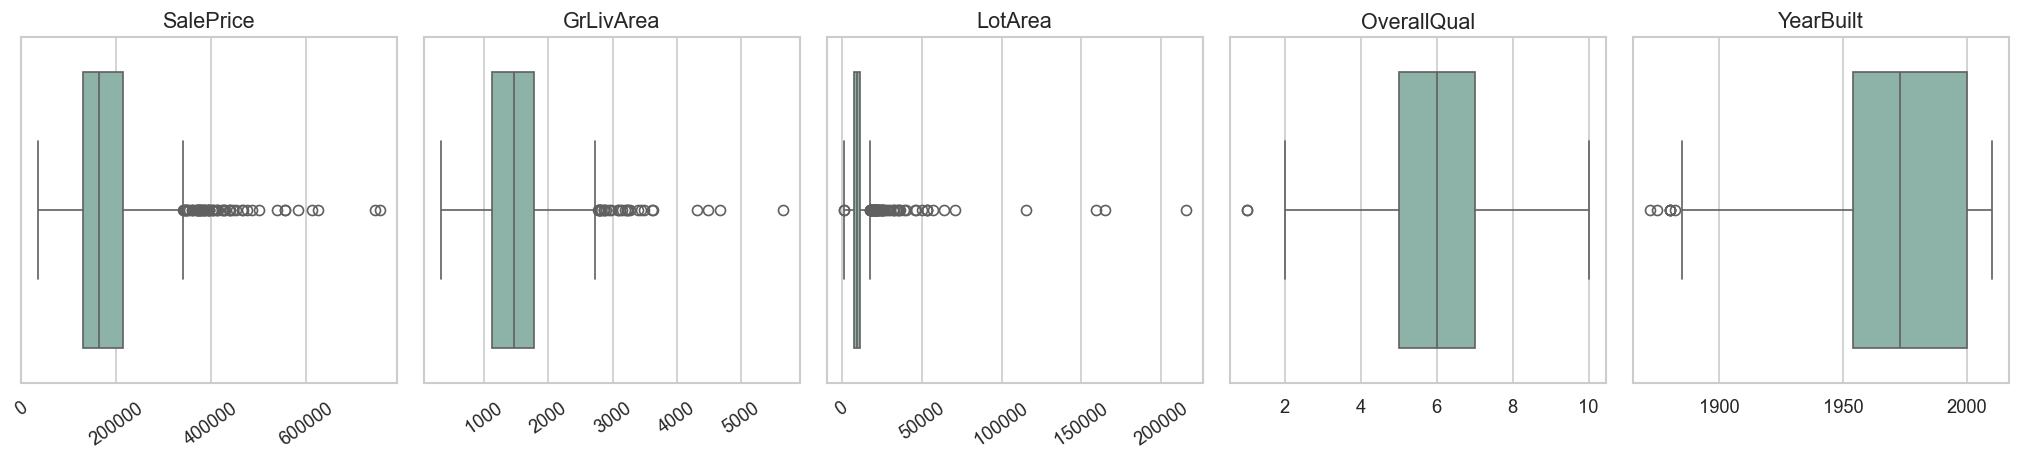

In [ ]:
key_continuous = ["SalePrice", "GrLivArea", "LotArea", "YearBuilt"]
summary=[]
for col in [*key_continuous, "OverallQual"]:
    x=train[col].dropna()
    summary.append({"feature":col,"n":len(x),"mean":x.mean(),"median":x.median(),"std":x.std(),"min":x.min(),"q1":x.quantile(.25),"q3":x.quantile(.75),"max":x.max(),"skewness":x.skew()})
display(pd.DataFrame(summary).round(2))
fig, axes=plt.subplots(2,2,figsize=(13,8))
for ax,col in zip(axes.flat,key_continuous):
    sns.histplot(train[col].dropna(),kde=True,bins=32,ax=ax,color="#3B82A0")
    ax.set_title(f"{col} | skew={train[col].skew():.2f}")
    if col=="LotArea": ax.set_xscale("log"); ax.set_xlabel("LotArea (sq ft, log scale)")
plt.tight_layout()
plt.show()

fig,axes=plt.subplots(1,5,figsize=(17,4))
for ax,col in zip(axes,["SalePrice","GrLivArea","LotArea","OverallQual","YearBuilt"]):
    sns.boxplot(x=train[col],ax=ax,color="#87B9AA",showfliers=True)
    ax.set_title(col); ax.set_xlabel("")
    if col in ["SalePrice","GrLivArea","LotArea"]: ax.tick_params(axis="x",labelrotation=35)
plt.tight_layout()
plt.show()

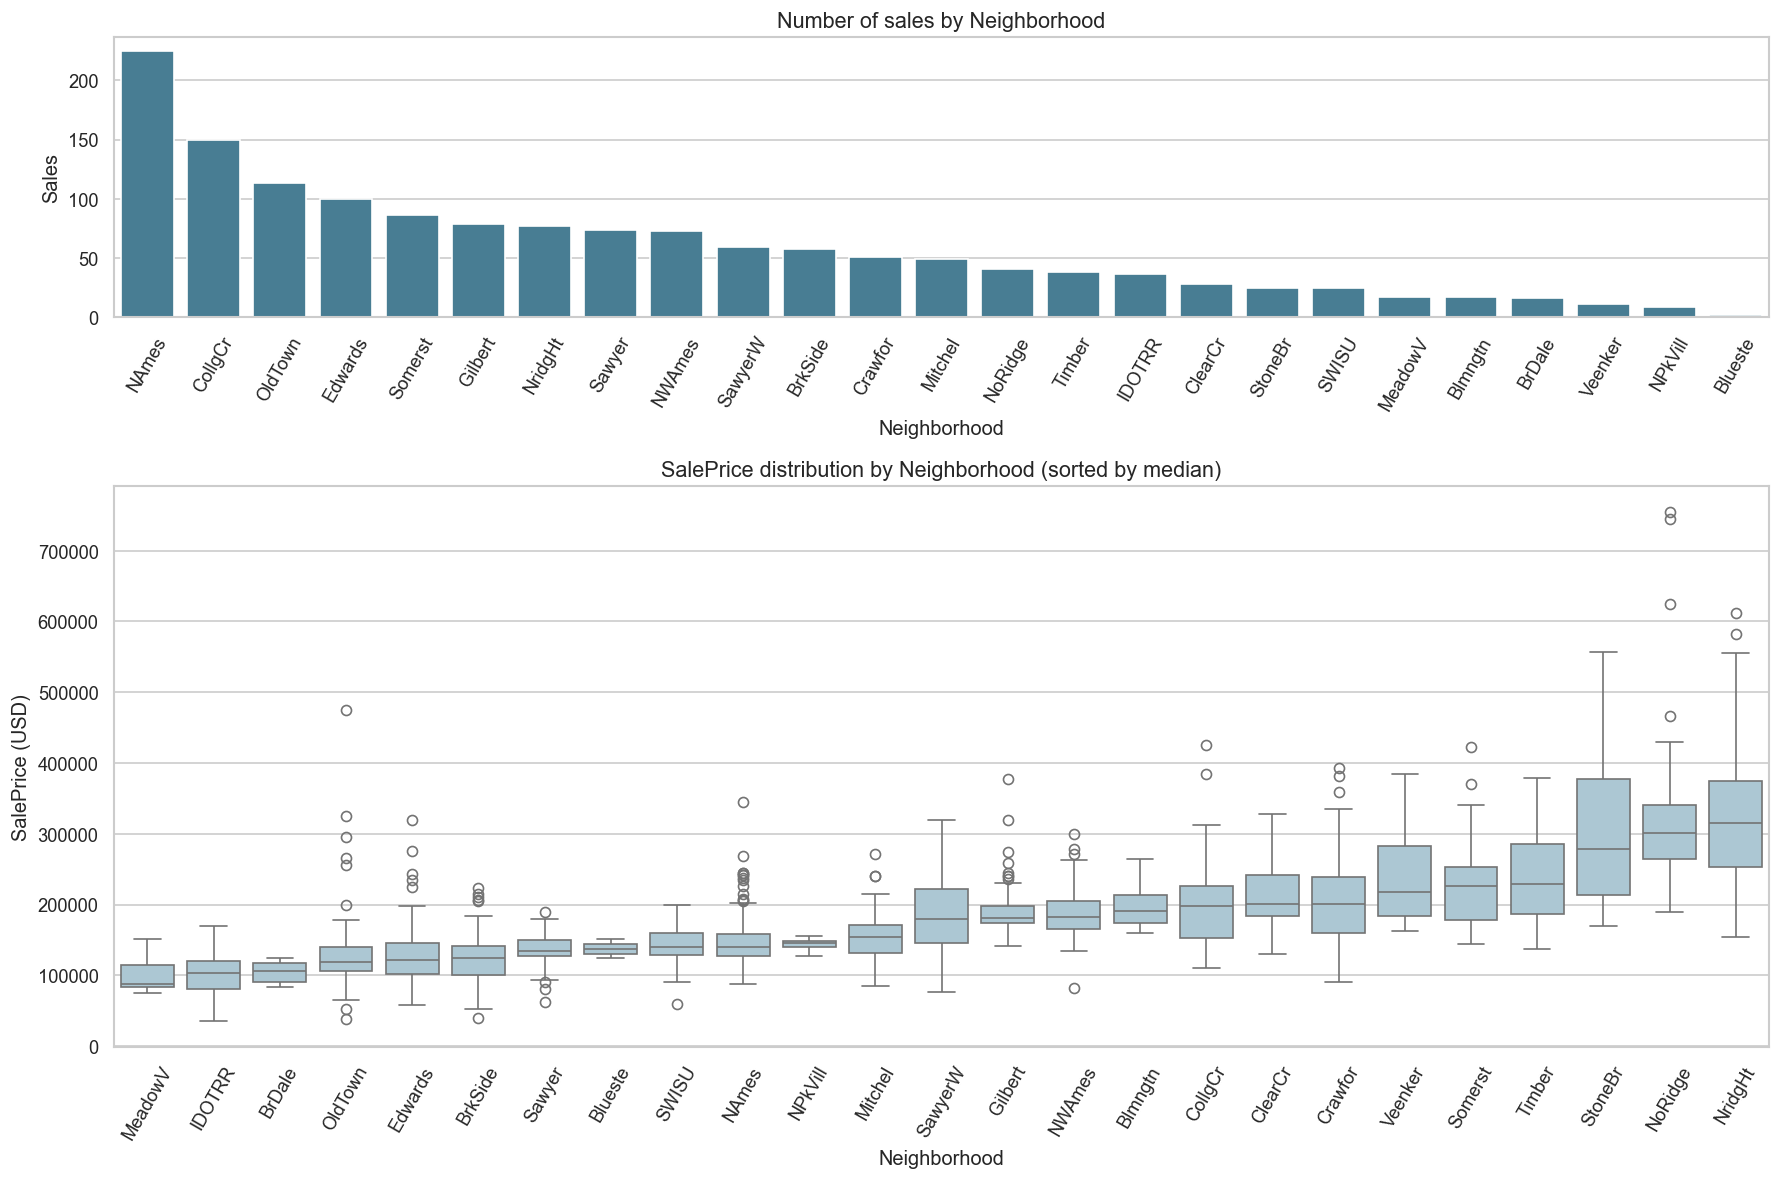

,n,median,mean
Neighborhood,,,
NridgHt,77,315000.0,316271.0
NoRidge,41,301500.0,335295.0
StoneBr,25,278000.0,310499.0
Timber,38,228475.0,242247.0
Somerst,86,225500.0,225380.0
Veenker,11,218000.0,238773.0
Crawfor,51,200624.0,210625.0
ClearCr,28,200250.0,212565.0
CollgCr,150,197200.0,197966.0


In [ ]:

fig,axes=plt.subplots(2,1,figsize=(15,10),gridspec_kw={"height_ratios":[1,2]})
counts=train.Neighborhood.value_counts().sort_values(ascending=False)
sns.barplot(x=counts.index,y=counts.values,ax=axes[0],color="#3B82A0")
axes[0].set_title("Number of sales by Neighborhood"); axes[0].set_ylabel("Sales"); axes[0].tick_params(axis="x",rotation=60)
medians=train.groupby("Neighborhood").SalePrice.median().sort_values()
sns.boxplot(data=train,x="Neighborhood",y="SalePrice",order=medians.index,ax=axes[1],color="#A5C9D9",showfliers=True)
axes[1].set_title("SalePrice distribution by Neighborhood (sorted by median)"); axes[1].set_ylabel("SalePrice (USD)"); axes[1].tick_params(axis="x",rotation=60)
plt.tight_layout(); plt.show()
display(train.groupby("Neighborhood").SalePrice.agg(n="size",median="median",mean="mean").sort_values("median",ascending=False).round(0))

## Task 3 — Bivariate analysis

Tập trung vào `SalePrice` và trả lời trực tiếp về diện tích, chất lượng, tuổi nhà, và Neighborhood. Các chart giữ outlier; phần sau cho phép xem độ nhạy khi loại nhóm được IQR đánh dấu.

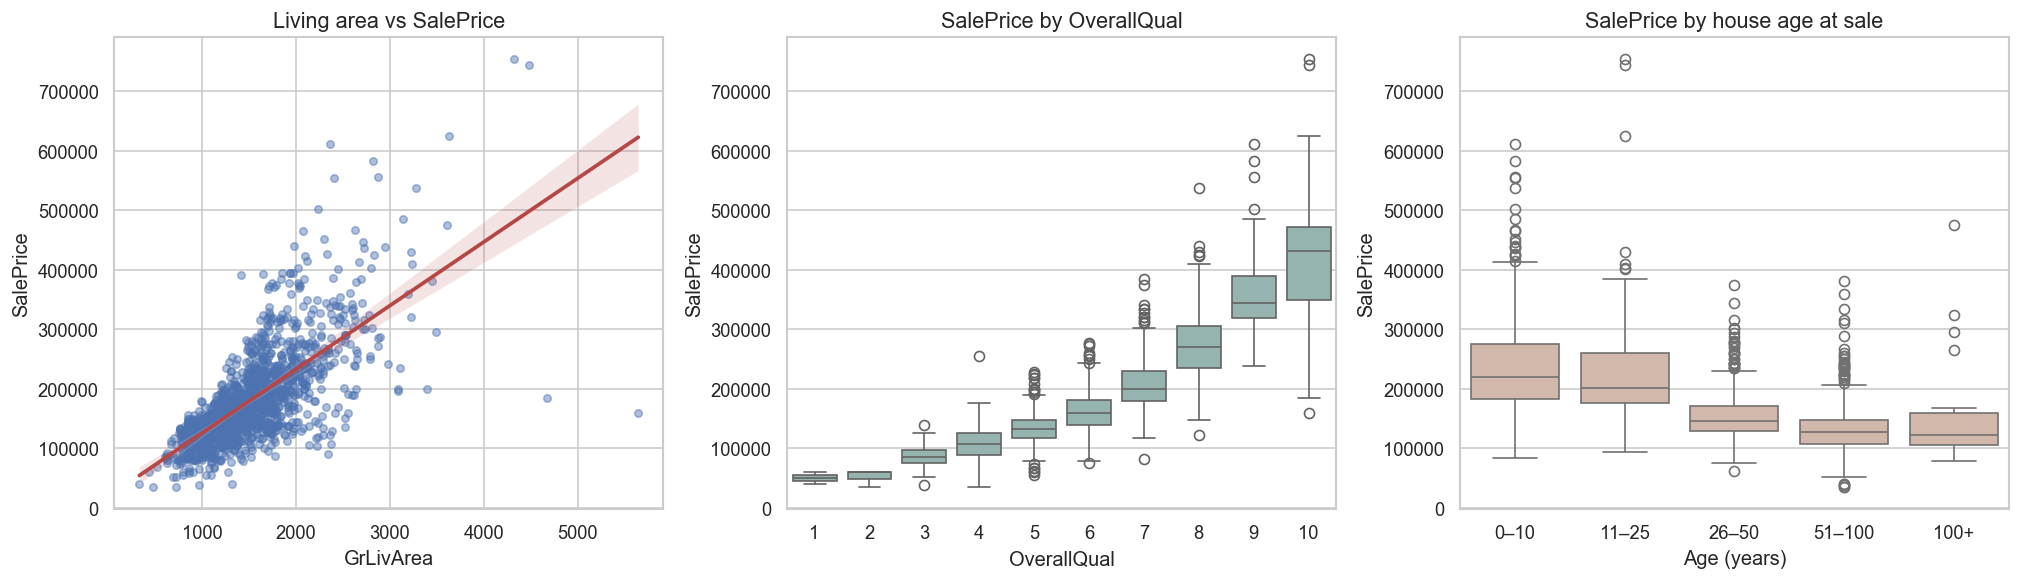

GrLivArea      Pearson r=0.709; Spearman rho=0.731
OverallQual    Pearson r=0.791; Spearman rho=0.810
YearBuilt      Pearson r=0.523; Spearman rho=0.653
LotArea        Pearson r=0.264; Spearman rho=0.456


,n,median,mean
HouseAgeGroup,,,
0–10,434,219355.0,238952.0
11–25,158,201750.0,226378.0
26–50,429,145500.0,153917.0
51–100,411,127000.0,132249.0
100+,28,123250.0,153118.0


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
sns.regplot(data=train,x="GrLivArea",y="SalePrice",scatter_kws={"alpha":.45,"s":20},line_kws={"color":"#B54747"},ax=axes[0]); axes[0].set_title("Living area vs SalePrice")
sns.boxplot(data=train,x="OverallQual",y="SalePrice",ax=axes[1],color="#91B9B3"); axes[1].set_title("SalePrice by OverallQual")
age_df=train.assign(HouseAgeAtSale=train.YrSold-train.YearBuilt)
age_df["HouseAgeGroup"]=pd.cut(age_df.HouseAgeAtSale,[-1,10,25,50,100,200],labels=["0–10","11–25","26–50","51–100","100+"])
sns.boxplot(data=age_df,x="HouseAgeGroup",y="SalePrice",ax=axes[2],color="#D7B6A3"); axes[2].set_title("SalePrice by house age at sale"); axes[2].set_xlabel("Age (years)")
plt.tight_layout(); plt.show()

for col in ["GrLivArea","OverallQual","YearBuilt","LotArea"]:
    print(f"{col:14s} Pearson r={train[col].corr(train.SalePrice):.3f}; Spearman rho={train[col].corr(train.SalePrice,method='spearman'):.3f}")
display(age_df.groupby("HouseAgeGroup",observed=True).SalePrice.agg(n="size",median="median",mean="mean").round(0))

## Task 4 — Multivariate analysis

Heatmap dùng numeric predictors, loại `Id` và target; bảng cặp có |Pearson r| hoặc |Spearman ρ| ≥ 0,60. Các cặp gần hoàn hảo của biến synthetic được đánh dấu là phụ thuộc do công thức tạo.

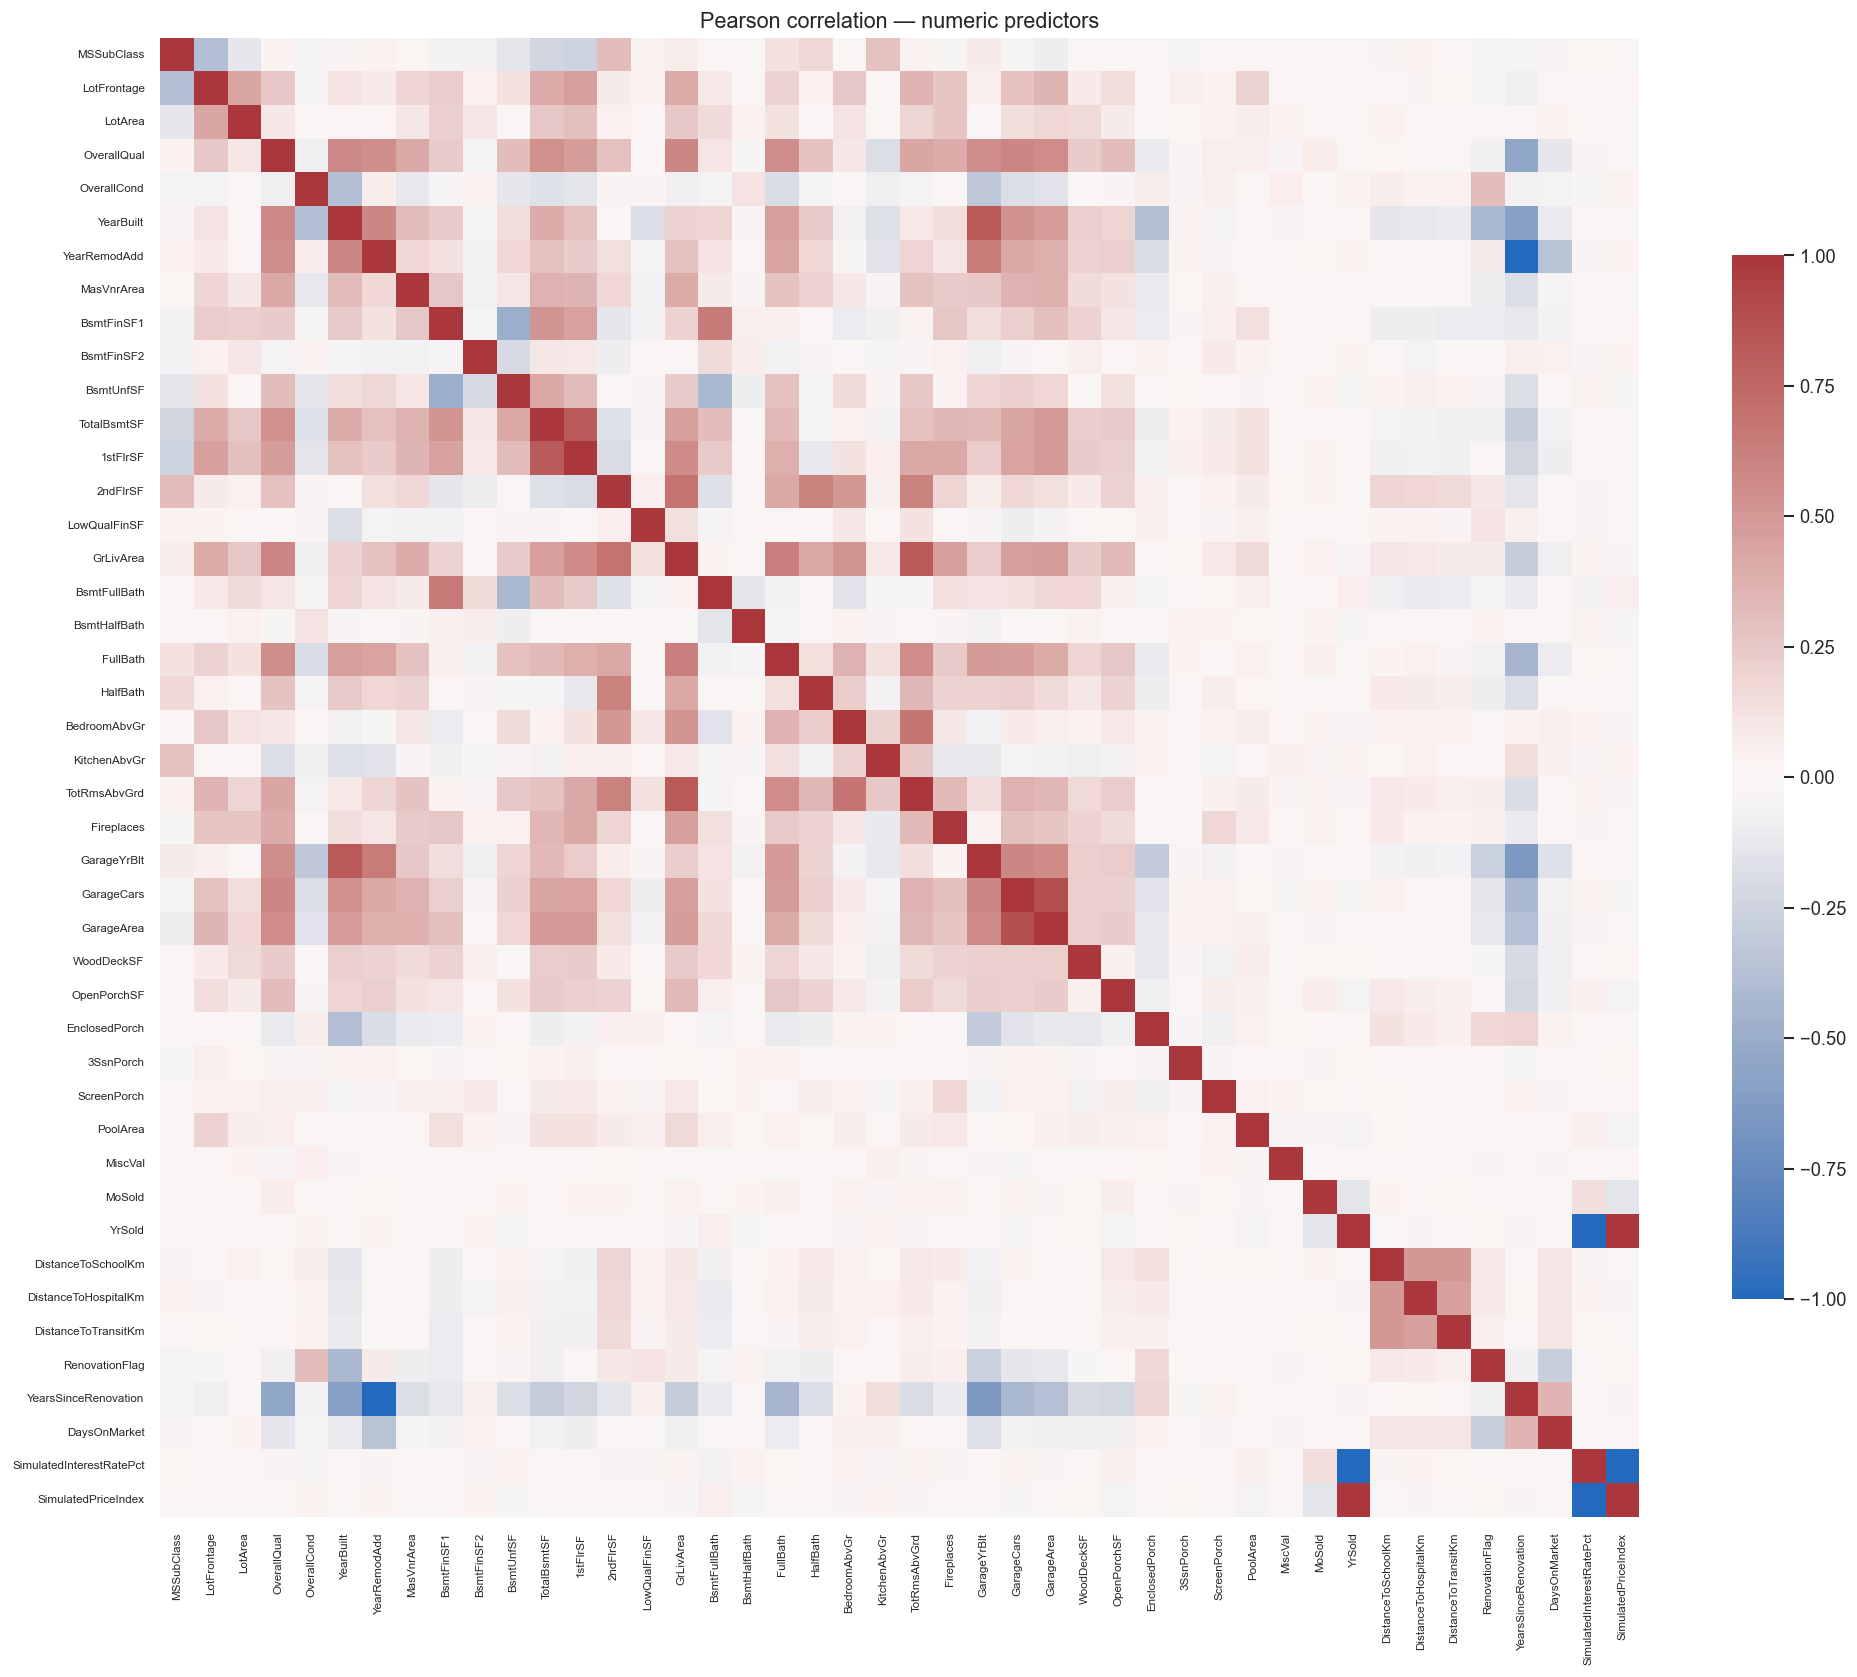

,feature_1,feature_2,pearson_r,spearman_rho
22,YrSold,SimulatedInterestRatePct,-1.000,-1.000
24,SimulatedInterestRatePct,SimulatedPriceIndex,-1.000,-1.000
23,YrSold,SimulatedPriceIndex,1.000,1.000
10,YearRemodAdd,YearsSinceRenovation,-0.998,-0.991
21,GarageCars,GarageArea,0.882,0.853
6,YearBuilt,GarageYrBlt,0.826,0.891
17,GrLivArea,TotRmsAbvGrd,0.825,0.828
12,TotalBsmtSF,1stFlrSF,0.820,0.829
13,2ndFlrSF,GrLivArea,0.688,0.643
18,BedroomAbvGr,TotRmsAbvGrd,0.677,0.668


In [ ]:
numeric_predictors=train.select_dtypes(include="number").columns.drop(["Id","SalePrice"],errors="ignore")
pearson=train[numeric_predictors].corr(method="pearson",min_periods=100)
spearman=train[numeric_predictors].corr(method="spearman",min_periods=100)
fig,ax=plt.subplots(figsize=(17,14)); sns.heatmap(pearson,cmap="vlag",center=0,vmin=-1,vmax=1,square=True,ax=ax,cbar_kws={"shrink":.7})
ax.set_title("Pearson correlation — numeric predictors"); ax.tick_params(axis="x",rotation=90,labelsize=7); ax.tick_params(axis="y",labelsize=7); plt.tight_layout(); plt.show()

pairs=[]
for i,a in enumerate(numeric_predictors):
    for b in numeric_predictors[i+1:]:
        r=train[a].corr(train[b]); rho=train[a].corr(train[b],method="spearman")
        if abs(r)>=.60 or abs(rho)>=.60: pairs.append({"feature_1":a,"feature_2":b,"pearson_r":r,"spearman_rho":rho})
pairs=pd.DataFrame(pairs)
if not pairs.empty: pairs=pairs.sort_values("pearson_r",key=lambda s:s.abs(),ascending=False)
display(pairs.round(3).head(25))

In [ ]:
# Price correlations include target; compare linear and rank association
price_rows=[]
for col in ["GrLivArea","OverallQual","YearBuilt","LotArea","GarageCars","GarageArea","TotRmsAbvGrd","TotalBsmtSF"]:
    price_rows.append({"feature":col,"Pearson r":train[col].corr(train.SalePrice),"Spearman rho":train[col].corr(train.SalePrice,method="spearman")})
display(pd.DataFrame(price_rows).set_index("feature").round(3).sort_values("Pearson r",ascending=False))

,Pearson r,Spearman rho
feature,,
OverallQual,0.791,0.810
GrLivArea,0.709,0.731
GarageCars,0.640,0.691
GarageArea,0.623,0.649
TotalBsmtSF,0.614,0.603
TotRmsAbvGrd,0.534,0.533
YearBuilt,0.523,0.653
LotArea,0.264,0.456


## Task 5 — Missing values & outliers

Missingness có thể đại diện cho một nhóm tài sản khác. IQR flag chỉ để phân tích độ nhạy, không tự động xóa khỏi dữ liệu chính.

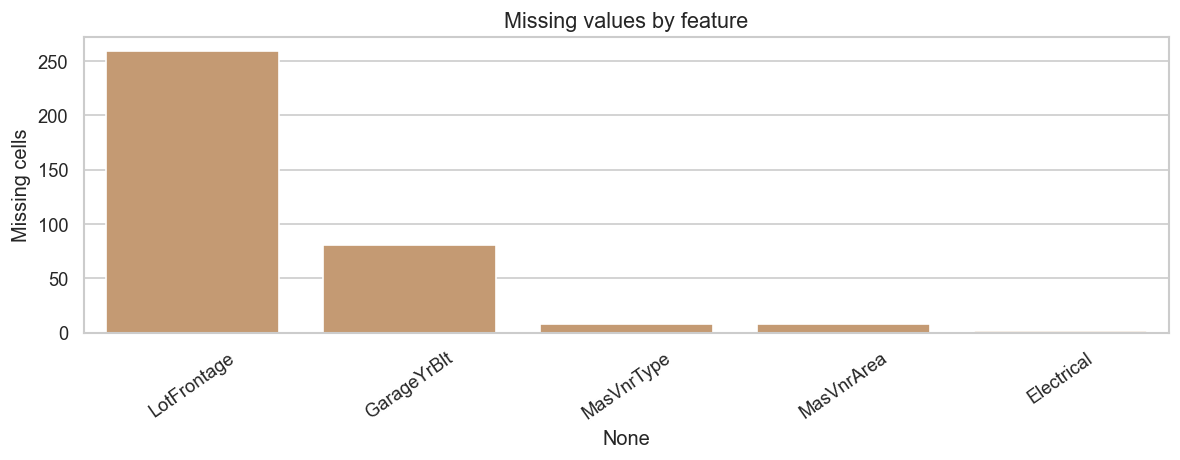

,feature,status,n,median SalePrice,mean SalePrice
0,LotFrontage,Missing,259,172400.0,181620.0
1,LotFrontage,Observed,1201,159500.0,180770.0
2,GarageYrBlt,Missing,81,100000.0,103317.0
3,GarageYrBlt,Observed,1379,167500.0,185480.0
4,MasVnrType,Missing,8,203287.0,236484.0
5,MasVnrType,Observed,1452,162700.0,180615.0
6,MasVnrArea,Missing,8,203287.0,236484.0
7,MasVnrArea,Observed,1452,162700.0,180615.0
8,Electrical,Missing,1,167500.0,167500.0
9,Electrical,Observed,1459,163000.0,180930.0


In [ ]:
missing=train.isna().sum().sort_values(ascending=False)
missing=missing[missing.gt(0)]
fig,ax=plt.subplots(figsize=(10,4)); sns.barplot(x=missing.index,y=missing.values,ax=ax,color="#D19A66")
ax.set_title("Missing values by feature"); ax.set_ylabel("Missing cells"); ax.tick_params(axis="x",rotation=35); plt.tight_layout(); plt.show()

missing_price=[]
for col in missing.index:
    for status,mask in [("Missing",train[col].isna()),("Observed",train[col].notna())]:
        vals=train.loc[mask,"SalePrice"]
        missing_price.append({"feature":col,"status":status,"n":len(vals),"median SalePrice":vals.median(),"mean SalePrice":vals.mean()})
display(pd.DataFrame(missing_price).round(0))

,feature,lower,upper,flagged,pct
0,SalePrice,3937.50,340037.50,61,4.18
1,GrLivArea,158.62,2747.62,31,2.12
2,LotArea,1481.50,17673.50,69,4.73
3,TotalBsmtSF,42.00,2052.00,61,4.18
4,GarageArea,-27.75,938.25,21,1.44


,cohort,n,median price,mean price,Pearson area-price,Spearman area-price
0,All,1460,163000.0,180921.196,0.709,0.731
1,Without SalePrice flags,1399,159500.0,170237.127,0.661,0.706
2,Without LotArea flags,1391,160000.0,178136.293,0.723,0.726
3,Without SalePrice/LotArea/GrLivArea flags,1328,157000.0,168135.190,0.690,0.697


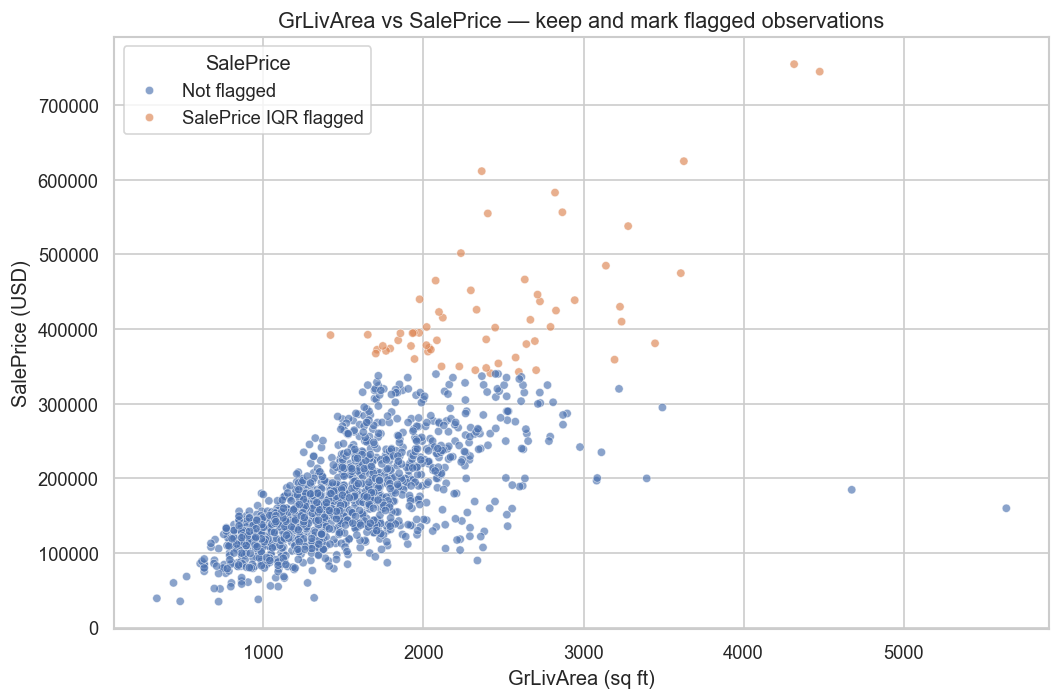

In [ ]:
outlier_cols=["SalePrice","GrLivArea","LotArea","TotalBsmtSF","GarageArea"]
flags=pd.DataFrame({"Id":train.Id})
thresholds=[]
for col in outlier_cols:
    q1,q3=train[col].quantile([.25,.75]); low=q1-1.5*(q3-q1); high=q3+1.5*(q3-q1)
    flags[col]=(train[col].lt(low)|train[col].gt(high))
    thresholds.append({"feature":col,"lower":low,"upper":high,"flagged":int(flags[col].sum()),"pct":100*flags[col].mean()})
display(pd.DataFrame(thresholds).round(2))

cohorts={"All":pd.Series(True,index=train.index),"Without SalePrice flags":~flags.SalePrice,"Without LotArea flags":~flags.LotArea,"Without SalePrice/LotArea/GrLivArea flags":~(flags.SalePrice|flags.LotArea|flags.GrLivArea)}
sensitivity=[]
for name,mask in cohorts.items():
    d=train.loc[mask]
    sensitivity.append({"cohort":name,"n":len(d),"median price":d.SalePrice.median(),"mean price":d.SalePrice.mean(),"Pearson area-price":d.GrLivArea.corr(d.SalePrice),"Spearman area-price":d.GrLivArea.corr(d.SalePrice,method="spearman")})
display(pd.DataFrame(sensitivity).round(3))

fig,ax=plt.subplots(figsize=(9,6))
sns.scatterplot(x=train.GrLivArea,y=train.SalePrice,hue=flags.SalePrice.map({True:"SalePrice IQR flagged",False:"Not flagged"}),alpha=.65,s=25,ax=ax)
ax.set_title("GrLivArea vs SalePrice — keep and mark flagged observations"); ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice (USD)"); plt.tight_layout(); plt.show()

## Task 6 — Synthetic Features Analysis

Các cột ở phần này được tạo theo giả định mô phỏng trong `docs/data_engineering/synthetic_assumptions.md`. Đọc association như kết quả kiểm tra logic/demonstration, không phải tác động đo được ngoài thực tế.

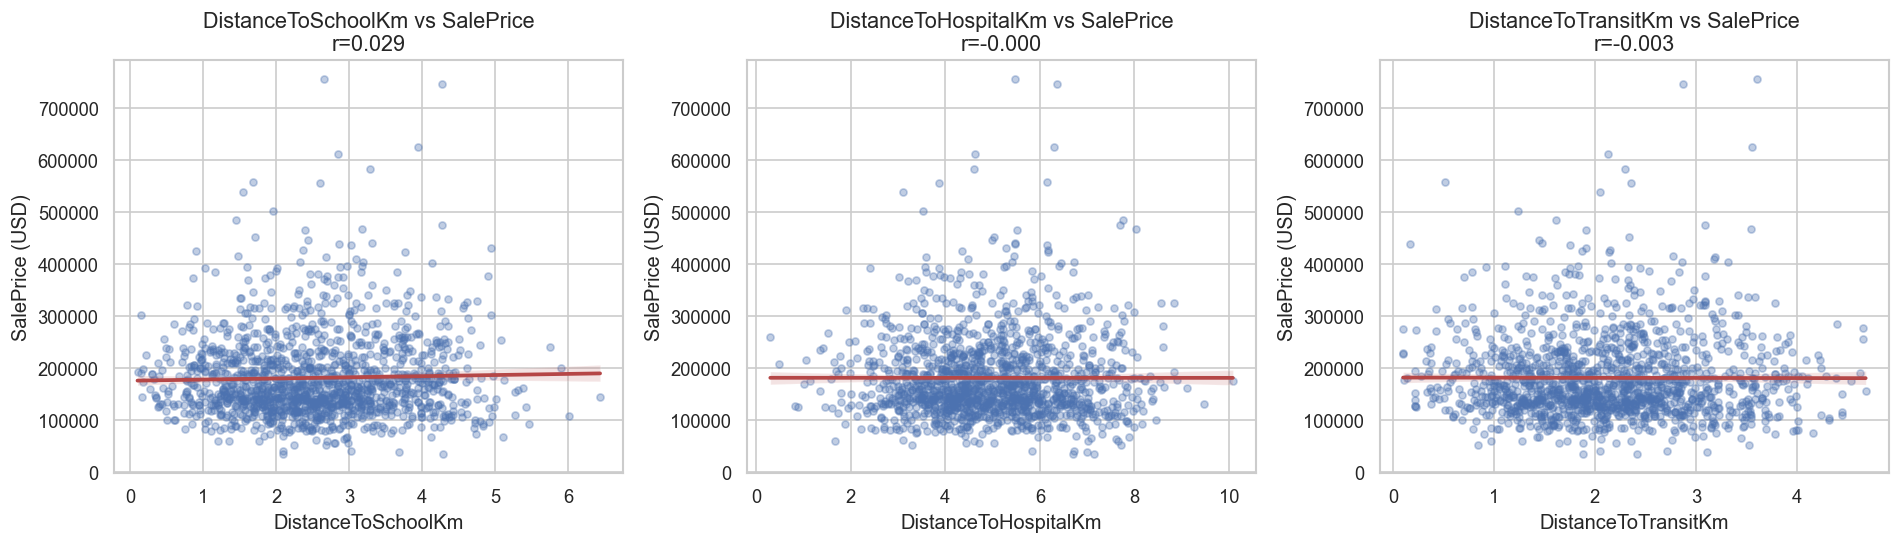

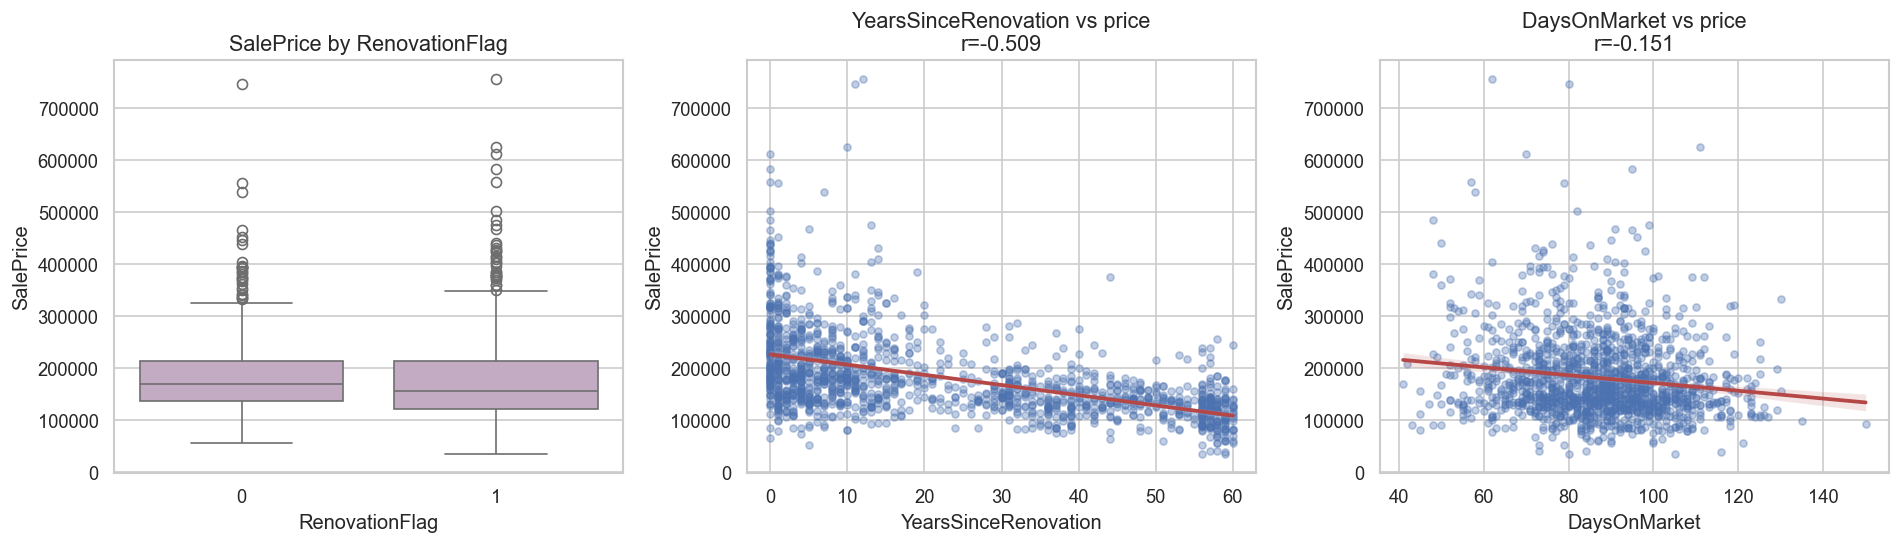

,feature,Pearson r,Spearman rho
0,DistanceToSchoolKm,0.029,0.012
1,DistanceToHospitalKm,-0.000,-0.023
2,DistanceToTransitKm,-0.003,-0.017
3,YearsSinceRenovation,-0.509,-0.577
4,DaysOnMarket,-0.151,-0.141
5,SimulatedInterestRatePct,0.029,0.030
6,SimulatedPriceIndex,-0.029,-0.030


,n,median,mean
RenovationFlag,,,
0,764,170000.0,182584.0
1,696,155000.0,179096.0


In [ ]:
synthetic_distance=["DistanceToSchoolKm","DistanceToHospitalKm","DistanceToTransitKm"]
fig,axes=plt.subplots(1,3,figsize=(16,4.7))
for ax,col in zip(axes,synthetic_distance):
    sns.regplot(data=train,x=col,y="SalePrice",scatter_kws={"alpha":.35,"s":18},line_kws={"color":"#B54747"},ax=ax)
    ax.set_title(f"{col} vs SalePrice\nr={train[col].corr(train.SalePrice):.3f}"); ax.set_ylabel("SalePrice (USD)")
plt.tight_layout(); plt.show()

fig,axes=plt.subplots(1,3,figsize=(16,4.7))
sns.boxplot(data=train,x="RenovationFlag",y="SalePrice",ax=axes[0],color="#C6A7C7"); axes[0].set_title("SalePrice by RenovationFlag")
sns.regplot(data=train,x="YearsSinceRenovation",y="SalePrice",scatter_kws={"alpha":.35,"s":18},line_kws={"color":"#B54747"},ax=axes[1]); axes[1].set_title(f"YearsSinceRenovation vs price\nr={train.YearsSinceRenovation.corr(train.SalePrice):.3f}")
sns.regplot(data=train,x="DaysOnMarket",y="SalePrice",scatter_kws={"alpha":.35,"s":18},line_kws={"color":"#B54747"},ax=axes[2]); axes[2].set_title(f"DaysOnMarket vs price\nr={train.DaysOnMarket.corr(train.SalePrice):.3f}")
plt.tight_layout(); plt.show()

synthetic_rows=[]
for col in synthetic_distance+["YearsSinceRenovation","DaysOnMarket","SimulatedInterestRatePct","SimulatedPriceIndex"]:
    synthetic_rows.append({"feature":col,"Pearson r":train[col].corr(train.SalePrice),"Spearman rho":train[col].corr(train.SalePrice,method="spearman")})
display(pd.DataFrame(synthetic_rows).round(3))
display(train.groupby("RenovationFlag").SalePrice.agg(n="size",median="median",mean="mean").round(0))

## Kết luận 

1. Diện tích sử dụng và đặc biệt OverallQual có liên hệ dương rõ với giá bán; các quan sát vẫn phân tán rộng.
2. Nhà mới hơn thường có median giá cao hơn trong mẫu; vị trí và chất lượng có thể giải thích một phần khác biệt.
3. Median giá khác đáng kể giữa Neighborhood; luôn trình bày kèm số lượng nhà để tránh diễn giải quá mức các nhóm nhỏ.
4. Một số biến numeric trùng lặp thông tin (garage capacity/area, diện tích nhà/số phòng); các biến synthetic theo năm gần như phụ thuộc công thức.
5. Outlier làm tăng mean giá và ảnh hưởng tương quan area-price; giữ dữ liệu gốc làm phân tích chính. Missing garage year cho thấy nhóm median thấp hơn rõ rệt, nên cần giữ missingness như thông tin nhóm.
6. Các distance synthetic gần như không tương quan với SalePrice ở lần mô phỏng này; không diễn giải như bằng chứng thực địa.

**Cleaning comparison:** notebook hiện kiểm tra trực tiếp header, thứ tự cột, `Id`, từng ô và SHA-256. Nếu hai file vẫn bằng nhau, kết luận là các artifact hiện hành không cho phép đo tác động cleaning.
